In [1]:
import tensorflow as tf
import numpy as np

In [2]:
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.fashion_mnist.load_data()
train_Ankit = {'images': train_images[:60000], 'labels': train_labels[:60000]}
test_Ankit = {'images': test_images[:10000], 'labels': test_labels[:10000]}

In [4]:
#Data Pre-processing
train_Ankit['images'] = train_Ankit['images'] / 255.0
test_Ankit['images'] = test_Ankit['images'] / 255.0

In [6]:
#printing shape of train and test images
print("Shape of train images:", train_Ankit['images'].shape)
print("Shape of test images:", test_Ankit['images'].shape)

Shape of train images: (60000, 28, 28)
Shape of test images: (10000, 28, 28)


In [7]:
from tensorflow.keras.layers import Layer

# Defining SampleLayer
class SampleLayer(Layer):
    def call(self, inputs):
        z_mu, z_log_sigma = inputs
        batch_size = tf.shape(z_mu)[0]
        dim = tf.shape(z_mu)[1]
        epsilon = tf.keras.backend.random_normal(shape=(batch_size, dim))
        print(dim)
        return z_mu + tf.exp(0.5 * z_log_sigma) * epsilon


In [8]:
# Build Encoder Section of VAE
input_img = tf.keras.layers.Input(shape=(28, 28, 1))

x = tf.keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same', strides=(2, 2))(x)
x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = tf.keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = tf.keras.layers.Flatten()(x)
x = tf.keras.layers.Dense(32, activation='relu')(x)

In [9]:
z_mu_Ankit = tf.keras.layers.Dense(2, name='z_mu_Ankit')(x)
z_log_sigma_Ankit = tf.keras.layers.Dense(2, name='z_log_sigma_Ankit')(x)
z_Ankit = SampleLayer()([z_mu_Ankit, z_log_sigma_Ankit])

Tensor("sample_layer/strided_slice_1:0", shape=(), dtype=int32)


In [10]:
encoder = tf.keras.models.Model(input_img, [z_mu_Ankit, z_log_sigma_Ankit, z_Ankit], name='encoder')

encoder.summary()


Model: "encoder"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 28, 28, 1)]  0           []                               
                                                                                                  
 conv2d (Conv2D)                (None, 28, 28, 32)   320         ['input_1[0][0]']                
                                                                                                  
 conv2d_1 (Conv2D)              (None, 14, 14, 64)   18496       ['conv2d[0][0]']                 
                                                                                                  
 conv2d_2 (Conv2D)              (None, 14, 14, 64)   36928       ['conv2d_1[0][0]']               
                                                                                            

In [11]:
from tensorflow.keras.utils import plot_model
plot_model(encoder, to_file='model.png', show_shapes=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [12]:
# Define decoder
latent_inputs = tf.keras.Input(shape=(2,))
x = tf.keras.layers.Dense(7 * 7 * 64, activation='relu')(latent_inputs)
x = tf.keras.layers.Reshape((7, 7, 64))(x)
x = tf.keras.layers.Conv2DTranspose(32, (3, 3), activation='relu', padding='same', strides=(2, 2))(x)
output_img = tf.keras.layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

decoder_Ankit = tf.keras.Model(latent_inputs, output_img, name='decoder_Ankit')
decoder_Ankit.summary()

plot_model(decoder_Ankit, to_file='decoder.png', show_shapes=True)

Model: "decoder_Ankit"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 2)]               0         
                                                                 
 dense_1 (Dense)             (None, 3136)              9408      
                                                                 
 reshape (Reshape)           (None, 7, 7, 64)          0         
                                                                 
 conv2d_transpose (Conv2DTra  (None, 14, 14, 32)       18464     
 nspose)                                                         
                                                                 
 conv2d_4 (Conv2D)           (None, 14, 14, 1)         289       
                                                                 
Total params: 28,161
Trainable params: 28,161
Non-trainable params: 0
_________________________________________________

In [13]:
# Define VAE
outputs = decoder_Ankit(encoder(input_img)[2])
vae_Ankit = tf.keras.Model(input_img, outputs, name='vae_Ankit')
vae_Ankit.summary()

plot_model(vae_Ankit, to_file='vae.png', show_shapes=True)

kl_loss = -0.5 * tf.reduce_mean(z_mu_Ankit - tf.square(z_mu_Ankit) - tf.exp(z_log_sigma_Ankit) + 1)

vae_Ankit.add_loss(kl_loss)

vae_Ankit.compile(optimizer='adam')

vae_Ankit.fit(train_Ankit['images'], epochs=10, batch_size=256,shuffle = True)

z_mean, _, _ = encoder.predict(test_Ankit['images'])

decoded_imgs = decoder_Ankit.predict(z_mean)

Tensor("encoder/sample_layer/strided_slice_1:0", shape=(), dtype=int32)
Model: "vae_Ankit"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 28, 28, 1)]       0         
                                                                 
 encoder (Functional)        [(None, 2),               494244    
                              (None, 2),                         
                              (None, 2)]                         
                                                                 
 decoder_Ankit (Functional)  (None, 14, 14, 1)         28161     
                                                                 
Total params: 522,405
Trainable params: 522,405
Non-trainable params: 0
_________________________________________________________________
You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.

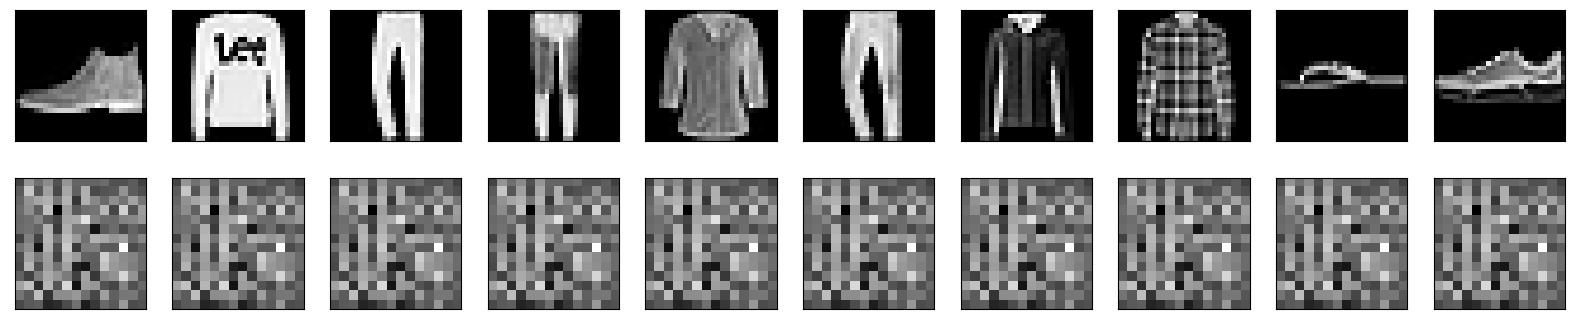

In [15]:
import matplotlib.pyplot as plt

n = 10
plt.figure(figsize=(20, 4))
for i in range(10):
    plt.gray()
    ax = plt.subplot(2, n, i+1)
    plt.imshow(test_Ankit['images'][i].reshape(28,28))
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
    ax = plt.subplot(2, n, i +1+n)
    plt.imshow(decoded_imgs[i].reshape(14,14,1))
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

In [16]:
from tensorflow.keras.models import Model

# latent space dimension

latent_dim = 2  
# build a model to generate the latent space for z_mu
latent_inputs = tf.keras.layers.Input(shape=(28, 28,), name='latent_inputs')
x = tf.keras.layers.Flatten()(latent_inputs)
x = tf.keras.layers.Dense(512, activation='relu')(x)
x = tf.keras.layers.Dense(256, activation='relu')(x)
z_mu_Ankit = tf.keras.layers.Dense(latent_dim, name='z_mu_Ankit')(x)
encoder_for_latent = tf.keras.Model(inputs=latent_inputs, outputs=z_mu_Ankit, name='encoder_for_latent')

z_mu_test = encoder_for_latent.predict(test_Ankit['images'])

313/313 [==============================] - 1s 4ms/step


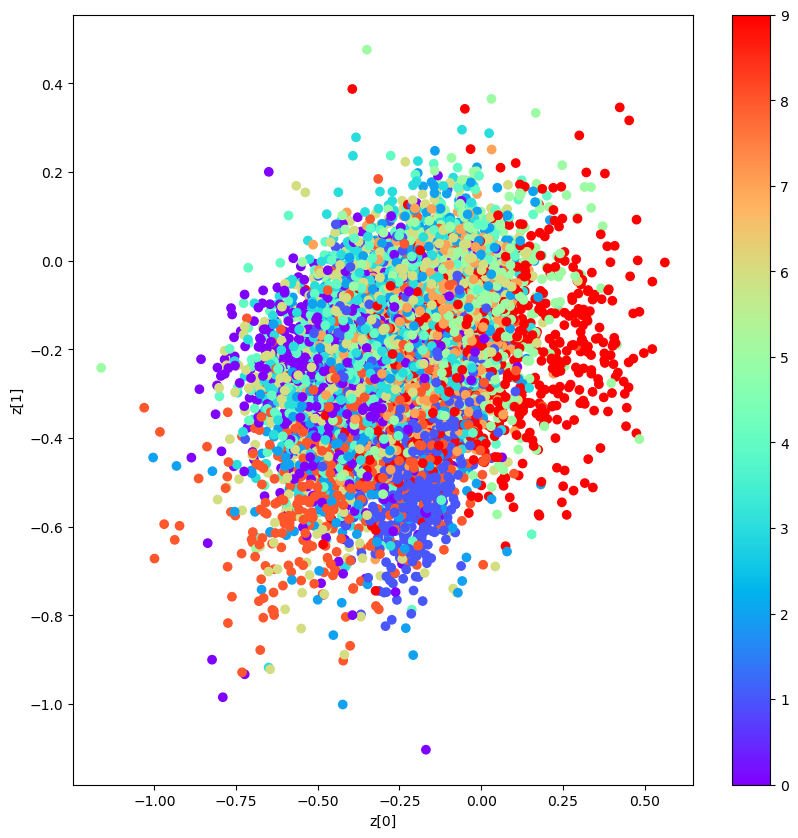

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
plt.scatter(z_mu_test[:, 0], z_mu_test[:, 1], c=test_labels, cmap='rainbow')
plt.colorbar()
plt.xlabel("z[0]")
plt.ylabel("z[1]")
plt.show()